# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Parking-Lot Incident Review

### Scenario

You are the new visual-analytics intern at **Northgate Tech Park Security**. Last night the camera over
Parking Lot B recorded something, and the Head of Security wants a briefing **today**. You have the 2-minute
camera log (`unit3_ppt1_cctv_log.csv`), the camera still, and 10 s of microphone audio. Their message to you:

1. *"Before anyone asks for 'just store everything in full HD', tell me how much data our 400 cameras would
   produce per day. I need real numbers."*
2. *"Our night camera images always look murky. Can you prove what's wrong with them and fix one?"*
3. *"I am not watching two minutes of video. Give me a timeline with the moments that matter and one
   picture per moment."*
4. *"Something banged around 75 s. Was it a **gunshot** or **breaking glass**? Those trigger completely
   different responses."*
5. *"Put it all on ONE screen for the briefing."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer
in your own words.

## Part 0 — Setup (given)

Run this cell as-is. It loads the camera log, the camera still, a frame renderer, and the audio (plus two
**reference recordings** from the security vendor's sound library: a known gunshot and a known glass break).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import cbook
from scipy import ndimage, signal

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

FPS, FS = 30, 16_000
cctv = pd.read_csv("unit3_ppt1_cctv_log.csv")
img = plt.imread(cbook.get_sample_data("grace_hopper.jpg")).astype(float)
lum = 0.299 * img[..., 0] + 0.587 * img[..., 1] + 0.114 * img[..., 2]
night_still = 18 + 0.22 * lum + np.random.normal(0, 1.5, lum.shape)        # what the night camera delivers

FRAME_H, FRAME_W = 90, 160
def render_frame(row):
    yy, xx = np.mgrid[0:FRAME_H, 0:FRAME_W]
    base = row.mean_brightness * (0.75 + 0.25 * yy / FRAME_H)
    frame = np.dstack([base, base, base * 1.05]); frame[60:62, :, :] += 25
    if not np.isnan(row.car_x):
        frame[(np.abs(xx - row.car_x / 4) < 14) & (np.abs(yy - row.car_y / 4) < 6)] = [200, 40, 40]
    if not np.isnan(row.person_x):
        frame[((xx - row.person_x / 4) / 2.2) ** 2 + ((yy - row.person_y / 4) / 5) ** 2 <= 1] = [30, 90, 230]
    return np.clip(frame, 0, 255).astype(np.uint8)

def _clip(kind, seed):
    rng = np.random.default_rng(seed)
    t = np.arange(int(2.0 * FS)) / FS
    x = 0.004 * rng.normal(size=t.size)
    m = t >= 0.5
    if kind == "gunshot":                       # sharp broadband crack + low boom, nothing after
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.02) * rng.normal(size=m.sum())
        x[m] += 0.5 * np.exp(-(t[m] - 0.5) / 0.25) * np.sin(2 * np.pi * 70 * (t[m] - 0.5))
    else:                                       # impact + lingering high-frequency tinkle
        x[m] += 0.9 * np.exp(-(t[m] - 0.5) / 0.03) * rng.normal(size=m.sum())
        for _ in range(40):
            t0 = 0.55 + rng.exponential(0.35); f0 = rng.uniform(3000, 7000)
            mk = (t >= t0) & (t < t0 + 0.06)
            x[mk] += 0.12 * np.exp(-(t[mk] - t0) / 0.015) * np.sin(2 * np.pi * f0 * (t[mk] - t0))
    return t, x

ref_gunshot = _clip("gunshot", 11)
ref_glass = _clip("glass", 12)
rng = np.random.default_rng(0)
t_audio = 70 + np.arange(10 * FS) / FS
x_audio = 0.02 * np.sin(2 * np.pi * 120 * t_audio) + 0.004 * rng.normal(size=t_audio.size)
_, unk = _clip("glass", 99)
x_audio[(t_audio >= 74.5) & (t_audio < 76.5)] += unk[: int(2 * FS)]           # the mystery sound

print(f"Camera log: {len(cctv):,} frames | still: {night_still.shape} | audio: {x_audio.size:,} samples at {FS} Hz")
cctv.head()

Camera log: 3,600 frames | still: (600, 512) | audio: 160,000 samples at 16000 Hz


,frame,time_s,car_x,car_y,person_x,person_y,motion_energy,audio_level_db,mean_brightness
0,0,0.0000,NaN,NaN,NaN,NaN,1.74,-53.3,62.1
1,1,0.0333,NaN,NaN,NaN,NaN,1.65,-53.0,64.4
2,2,0.0667,NaN,NaN,NaN,NaN,1.64,-51.5,63.2
3,3,0.1000,NaN,NaN,NaN,NaN,1.96,-52.9,63.1
4,4,0.1333,NaN,NaN,NaN,NaN,1.61,-51.1,62.4


## Task 1 — The Storage Reality Check (Request #1)

**Real-world usage:** Storage budgets for camera fleets are decided from exactly these back-of-envelope numbers.

**Why this technique:** Uncompressed storage = **W × H × C × B** per frame (Slides 25–28), frames = **f × T**
(Slide 35), audio samples = **f_s × T** (Slide 55).

**TODO:**
1. Compute the uncompressed size (in MB) of ONE 1920 × 1080 RGB frame at 8 bits per channel.
2. Compute the number of frames ONE camera records in 24 h at 30 fps.
3. Compute the total uncompressed video for 400 cameras for 24 h, in **terabytes** (1 TB = 1024⁴ bytes).
4. Compute the same total if the cameras were downsampled to 640 × 360 and 10 fps. What percentage of the
   pixels per frame remain after the downsample?

In [2]:
# TODO 1: one 1080p RGB frame, in MB
frame_bytes = 1920 * 1080 * 3 * 1            # W x H x C x B (8 bits = 1 byte per channel)
frame_mb = frame_bytes / 1024**2

# TODO 2: frames per camera per day at 30 fps
frames_per_day = 30 * 24 * 3600              # f x T

# TODO 3: 400 cameras x 24 h, uncompressed, in TB
fleet_tb = frame_bytes * frames_per_day * 400 / 1024**4

# TODO 4: same fleet at 640x360 and 10 fps (TB), and % of pixels per frame that remain
small_frame_bytes = 640 * 360 * 3
fleet_tb_small = small_frame_bytes * (10 * 24 * 3600) * 400 / 1024**4
pct_pixels_remaining = (640 * 360) / (1920 * 1080) * 100

print(f"One frame: {frame_mb:.2f} MB | frames/day: {frames_per_day:,}")
print(f"Fleet (1080p, 30 fps): {fleet_tb:,.1f} TB/day | Fleet (360p, 10 fps): {fleet_tb_small:,.1f} TB/day")
print(f"Pixels per frame remaining after downsample: {pct_pixels_remaining:.2f}%")

One frame: 5.93 MB | frames/day: 2,592,000
Fleet (1080p, 30 fps): 5,866.0 TB/day | Fleet (360p, 10 fps): 217.3 TB/day
Pixels per frame remaining after downsample: 11.11%


**Reflection:** Downsampling to 360p/10 fps saves a huge amount of storage. Using Slides 13 and 36–37
(raster interpolation; frame rate and the correspondence problem), name **one spatial** and **one temporal**
piece of evidence the security team could lose forever by making that choice.

_Your answer:_

**Spatial (Slide 13, raster interpolation):** at 640x360 only 11.11% of the pixels remain (a 3x reduction per axis), so fine detail
such as a **licence-plate number, a face or a logo on clothing** is averaged away. Interpolation can make the image
*look* smooth again when it is scaled back up, but it cannot recreate detail that was never stored.

**Temporal (Slides 36-37, frame rate and correspondence):** at 10 fps the gap between frames is 100 ms instead of 33 ms.
In the log the person goes from standing to running at about 78 s. At 10 fps there are far fewer frames covering
that transition and any fast movement (a swung arm, a thrown object, a hand reaching for a car door). Between frames
the displacement can be large enough that the correspondence problem becomes ambiguous: we can no longer be sure
which blob in frame t+1 is the same object as in frame t, so the exact sequence of actions and the motion path are lost.

## Task 2 — Diagnose and Fix the Murky Night Image (Request #2)

**Real-world usage:** Before anyone interprets a night image, an analyst checks its histogram to see whether
the problem is exposure, contrast or clipping.

**Why this technique:** The **histogram** shows the intensity distribution (Slides 16–18); **Michelson
contrast** C = (L_max − L_min)/(L_max + L_min) quantifies it (Slide 15); a **contrast stretch** remaps the
occupied range onto 0–255.

**TODO:**
1. Plot `night_still` and its histogram (64 bins, range 0–255) side by side.
2. Compute its Michelson contrast using the 1st and 99th percentiles as L_min and L_max (robust to outliers).
3. Contrast-stretch it: map the 1st percentile → 0 and the 99th percentile → 255 (clip to 0–255).
4. Plot the stretched image + histogram, and print the new contrast.

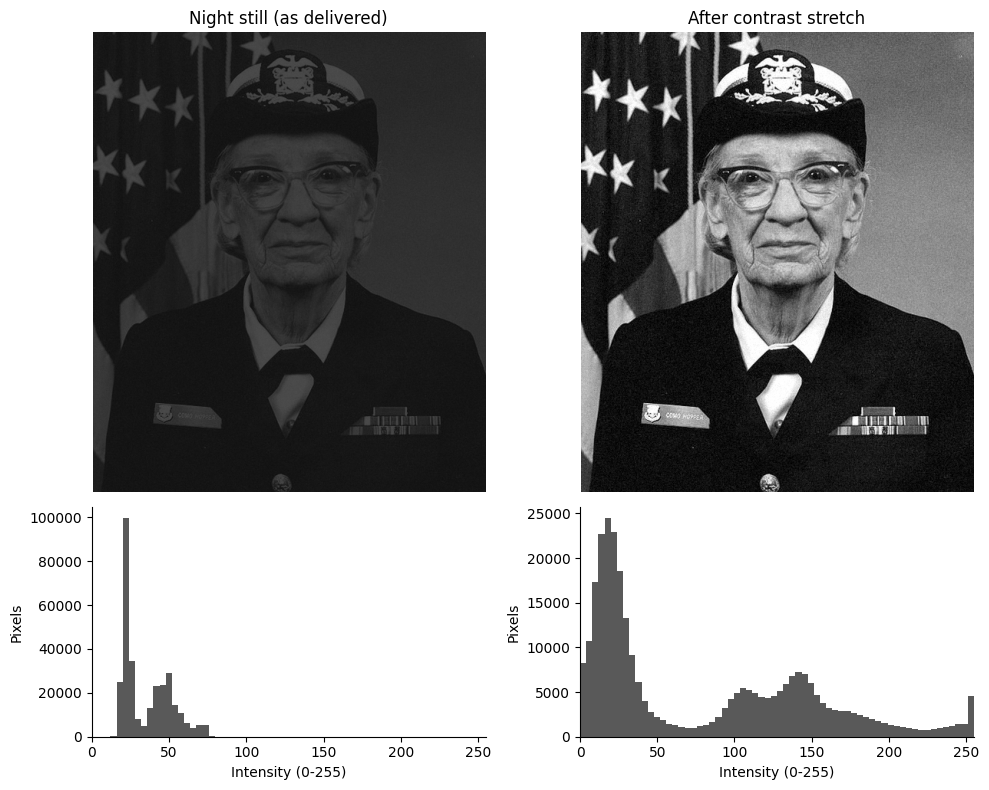

Contrast before: 0.609  ->  after: 1.000


In [3]:
def michelson(lmax, lmin):
    return (lmax - lmin) / (lmax + lmin)

# TODO 2: robust Michelson contrast of night_still
lo, hi = np.percentile(night_still, [1, 99])
c_before = michelson(hi, lo)

# TODO 3: contrast-stretched version of night_still
stretched = np.clip((night_still - lo) / (hi - lo) * 255, 0, 255)

lo2, hi2 = np.percentile(stretched, [1, 99])
c_after = michelson(hi2, lo2)

fig, axes = plt.subplots(2, 2, figsize=(10, 8), gridspec_kw={"height_ratios": [2, 1]})
# TODO 1 & 4: top row = images, bottom row = histograms (before | after)
for col, (im, title) in enumerate([(night_still, "Night still (as delivered)"),
                                   (stretched, "After contrast stretch")]):
    axes[0, col].imshow(im, cmap="gray", vmin=0, vmax=255)
    axes[0, col].set_title(title); axes[0, col].axis("off")
    axes[1, col].hist(im.ravel(), bins=64, range=(0, 255), color="0.35")
    axes[1, col].set_xlim(0, 255)
    axes[1, col].set_xlabel("Intensity (0-255)"); axes[1, col].set_ylabel("Pixels")

plt.tight_layout(); plt.show()
print(f"Contrast before: {c_before:.3f}  ->  after: {c_after:.3f}")

**Reflection:** Describe the *shape* of the night image's histogram in the lecture's vocabulary (Slide 18 table).
Then explain why stretching made the image readable even though it added **no new information** — and why a
histogram alone could never have told you *what* is in the picture (Slide 18, "Same Histogram ≠ Same Image").

_Your answer:_

**Shape:** the night histogram is a **narrow, dark-skewed (low-key) distribution**: all pixels are packed into a small
band at the low end of the 0-255 axis (roughly 13-79, most of it below about 50), with nothing near white. In the Slide 18 vocabulary this is an
**underexposed / low-contrast** image. It uses only about a quarter of the available 256 levels (Michelson 0.61 is misleading here because both L_min and L_max are small numbers; the stretch brings it to 1.00), and the image is
not clipped because there is no pile-up at 0 or 255, so the problem is a *narrow range*, not lost data.

**Why stretching helped without adding information:** the scene detail is already in the pixels as small differences
between neighbouring intensity values, which the eye cannot resolve in a narrow dark band. Stretching is just a linear remap that
spreads the occupied range (1st-99th percentile) over 0-255. Differences get bigger, so structure becomes visible.
Every pixel's rank order is preserved, so no new information is created (noise is amplified along with the signal).

**Why the histogram cannot tell what is in the picture:** a histogram only counts *how many* pixels have each intensity and
discards *where* they are. Many different images share one histogram (shuffle the pixels and it stays identical), so
the histogram can diagnose exposure and contrast but not content (Slide 18, "Same Histogram != Same Image").

## Task 3 — From Two Minutes of Video to a One-Glance Timeline (Request #3)

**Real-world usage:** Security reviewers search for events; they don't watch footage linearly.

**Why this technique:** **Motion vectors → events → timeline + representative frames** (Slides 38–40, 45, 47).
Content-based keyframes beat uniform sampling when activity is sparse.

**TODO:**
1. Compute the person's speed in px/s as the magnitude of their motion vector over a 1-second window
   (`diff(FPS)` on x and y — single-frame differences are dominated by tracking jitter).
2. Find the time ranges where the person is **standing** (speed < 3 px/s) and **running** (speed > 25 px/s).
3. Detect the frames where `audio_level_db` first rises above −20 dB and where `mean_brightness` jumps by more
   than 40 in one frame.
4. Plot a timeline of `motion_energy` with a vertical marker + label for each event you found.
5. Show **one keyframe per event** (use `render_frame(cctv.iloc[i])`).

Standing (<3 px/s):  68.7 s -> 78.1 s
Running  (>25 px/s): 78.6 s -> 86.0 s
Audio event: frame 2250 (t = 75.00 s)
Lighting event: frame 3000 (t = 100.00 s)


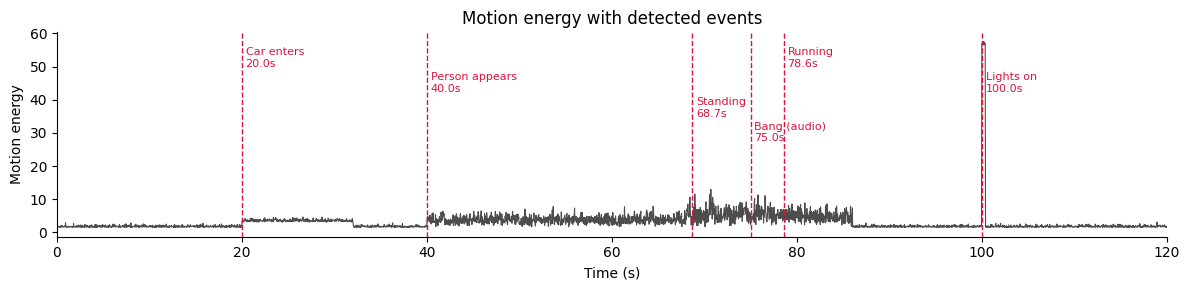

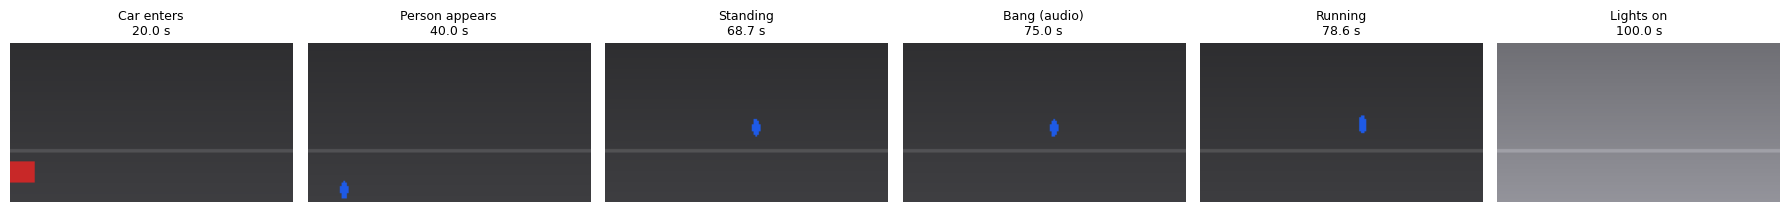

In [4]:
# TODO 1: person speed (px/s)
# diff(FPS) = displacement over 1 s, so the value is already in px/s (NaN while the person is not in view)
speed = np.hypot(cctv.person_x.diff(FPS), cctv.person_y.diff(FPS))
cctv["speed"] = speed

# TODO 2: standing / running time ranges (print the first and last time of each)
standing = cctv.time_s[speed < 3]
running = cctv.time_s[speed > 25]
print(f"Standing (<3 px/s):  {standing.min():.1f} s -> {standing.max():.1f} s")
print(f"Running  (>25 px/s): {running.min():.1f} s -> {running.max():.1f} s")

# TODO 3: event frame indices
audio_event_idx = int((cctv.audio_level_db > -20).idxmax())            # first frame above -20 dB
lighting_event_idx = int(cctv.index[cctv.mean_brightness.diff() > 40][0])   # brightness jump > 40 in one frame
print(f"Audio event: frame {audio_event_idx} (t = {cctv.time_s[audio_event_idx]:.2f} s)")
print(f"Lighting event: frame {lighting_event_idx} (t = {cctv.time_s[lighting_event_idx]:.2f} s)")

events = {
    "Car enters":      int(cctv.car_x.first_valid_index()),
    "Person appears":  int(cctv.person_x.first_valid_index()),
    "Standing":        int(standing.index[0]),
    "Bang (audio)":    audio_event_idx,
    "Running":         int(running.index[0]),
    "Lights on":       lighting_event_idx,
}

# TODO 4: annotated motion-energy timeline
fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(cctv.time_s, cctv.motion_energy, lw=0.8, color="0.3")
ymax = cctv.motion_energy.max()
for k, (name, i) in enumerate(events.items()):
    t = cctv.time_s[i]
    ax.axvline(t, color="crimson", ls="--", lw=1)
    ax.text(t + 0.4, ymax * (0.97 - 0.13 * (k % 4)), f"{name}\n{t:.1f}s", color="crimson", fontsize=8, va="top")
ax.set_xlabel("Time (s)"); ax.set_ylabel("Motion energy"); ax.set_xlim(0, 120)
ax.set_title("Motion energy with detected events")
plt.tight_layout(); plt.show()

# TODO 5: one keyframe per event
fig, axes = plt.subplots(1, len(events), figsize=(3 * len(events), 2.4))
for ax, (name, i) in zip(axes, events.items()):
    ax.imshow(render_frame(cctv.iloc[i])); ax.axis("off")
    ax.set_title(f"{name}\n{cctv.time_s[i]:.1f} s", fontsize=9)
plt.tight_layout(); plt.show()

**Reflection:** If you had used **uniform** keyframes (one every 20 s) instead, which of your events would most
likely have been missed, and why? Which lecture concept (Slide 40) names the approach you used instead?

_Your answer:_

With one frame every 20 s (t = 0, 20, 40, 60, 80, 100) the **bang at about 75 s** and the **start of the run at about 78 s** would
almost certainly be missed. The bang lasts well under a second (a short spike in the audio and motion traces) and the
run begins in a few seconds, so they fall between the samples. The 80 s frame would show the person already
running with no cue about what triggered it, while the 100 s frame happens to catch the lights coming on only
by luck. Uniform sampling is blind to *when* things happen and spends most frames on the empty lot.

The approach I used is **content-based keyframe selection** (Slide 40): frames are chosen *because* the signal changed
(motion, audio or brightness jump), so keyframes are dense where activity is dense and sparse where nothing happens.

## Task 4 — Gunshot or Glass? (Request #4)

**Real-world usage:** Acoustic event classification in security systems starts with an analyst comparing
spectrogram signatures against known references.

**Why this technique:** A **waveform** shows *when* something loud happened but not *what* it was; a
**spectrogram** (Slides 56–58) reveals each sound's time–frequency signature.

**TODO:**
1. Plot the waveforms of `ref_gunshot`, `ref_glass` and the mystery segment of `x_audio` (74.5–76.5 s).
2. Plot their spectrograms (use `signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)`, show in dB,
   y-axis 0–8000 Hz).
3. Compute, for each clip, the fraction of spectral energy **above 3 kHz** in the 0.2–1.2 s after the impact.
4. Print a one-line verdict.

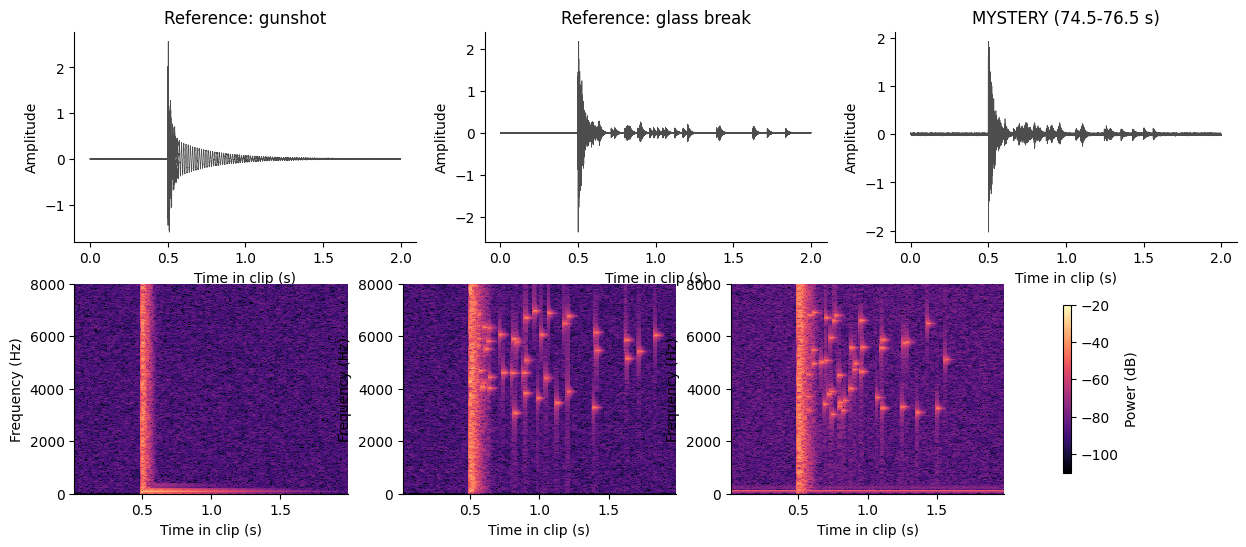

{'Reference: gunshot': 0.003, 'Reference: glass break': 0.989, 'MYSTERY (74.5-76.5 s)': 0.873}
Verdict: the mystery sound is a GLASS BREAK (high-frequency energy fraction 0.87 vs glass 0.99 and gunshot 0.00).


In [5]:
mystery = x_audio[(t_audio >= 74.5) & (t_audio < 76.5)]
clips = {"Reference: gunshot": ref_gunshot[1], "Reference: glass break": ref_glass[1], "MYSTERY (74.5-76.5 s)": mystery}

fig, axes = plt.subplots(2, 3, figsize=(15, 6))
# TODO 1 & 2: waveform (top row) and spectrogram (bottom row) for each clip
t_clip = np.arange(int(2.0 * FS)) / FS
for k, (name, x) in enumerate(clips.items()):
    axes[0, k].plot(t_clip, x, lw=0.5, color="0.3")
    axes[0, k].set_title(name); axes[0, k].set_xlabel("Time in clip (s)"); axes[0, k].set_ylabel("Amplitude")
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    im = axes[1, k].pcolormesh(tt, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-20)
    axes[1, k].set_ylim(0, 8000)
    axes[1, k].set_xlabel("Time in clip (s)"); axes[1, k].set_ylabel("Frequency (Hz)")
fig.colorbar(im, ax=axes[1, :], label="Power (dB)", shrink=0.8)

plt.show()

# TODO 3: fraction of energy above 3 kHz, 0.2-1.2 s after the impact (impact is at 0.5 s in every clip)
def hf_frac(x):
    f, tt, Sxx = signal.spectrogram(x, fs=FS, nperseg=512, noverlap=384)
    win = (tt >= 0.5 + 0.2) & (tt <= 0.5 + 1.2)
    S = Sxx[:, win]
    return S[f > 3000].sum() / S.sum()

hf_fraction = {name: round(float(hf_frac(x)), 3) for name, x in clips.items()}

print(hf_fraction)
# TODO 4: verdict
g, gl, m = hf_fraction["Reference: gunshot"], hf_fraction["Reference: glass break"], hf_fraction["MYSTERY (74.5-76.5 s)"]
verdict = "GLASS BREAK" if abs(m - gl) < abs(m - g) else "GUNSHOT"
print(f"Verdict: the mystery sound is a {verdict} (high-frequency energy fraction {m:.2f} vs glass {gl:.2f} and gunshot {g:.2f}).")

**Reflection:** Look only at the three **waveforms**. Could you have confidently told the gunshot from the glass
break? What exactly does the spectrogram add (name the three dimensions from Slide 57), and which visual pattern
(horizontal band / vertical stripe / scattered high-frequency specks) decided your verdict?

_Your answer:_

**Waveforms only: no.** All three show the same picture: a near-silent baseline, then a sudden loud spike at the impact
(0.5 s) that decays. The envelopes differ only subtly, so I could not confidently separate the gunshot from the glass break.
A waveform tells us *when* and *how loud*, not *what kind of sound*.

**What the spectrogram adds (Slide 57):** its three dimensions are **time** (x-axis), **frequency** (y-axis) and
**magnitude / intensity** (colour). It shows *which frequencies* carry the energy and *how that changes over time*.

**Deciding pattern:** the gunshot shows a **vertical stripe** (a broadband crack that is all over in a moment) plus a low
boom, and then silence; almost no energy stays above 3 kHz afterwards. The glass break shows the same initial stripe
followed by **scattered high-frequency specks** (the tinkle of falling shards, 3-7 kHz) that continue for about a second.
The mystery clip has those scattered high-frequency specks and a high above-3 kHz energy fraction that matches the
glass reference, so my verdict is **breaking glass**. No horizontal band appeared, which would indicate a steady tone such as an alarm or an engine.

## Task 5 — The One-Screen Briefing (Request #5)

**Real-world usage:** Incident briefings use a synchronized multimodal view so every claim is backed by two
modalities at the same timestamp.

**Why this technique:** **Image–video–audio integration** linked through a common time reference
(Slide 59), with **overview first** (timeline) and detail at the selected moment.

**TODO:** Build ONE figure with:
1. the rendered video frame at t = 75 s (left),
2. the full 120 s motion + audio timeline with a red marker at 75 s (top right),
3. the spectrogram of `x_audio` (70–80 s) with the same marker (bottom right),
4. a conclusion-style figure title (what happened, not "Incident Dashboard").

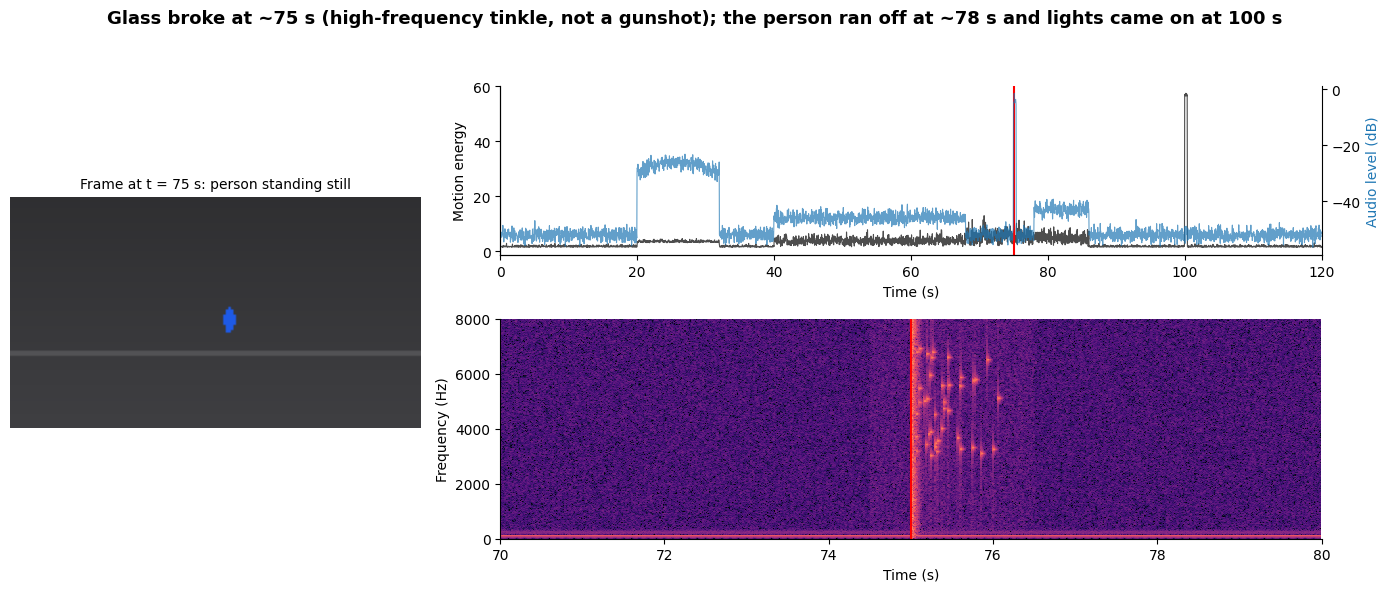

In [6]:
t_sel = 75.0
fig = plt.figure(figsize=(14, 6))
gs = fig.add_gridspec(2, 2, width_ratios=[1, 2], height_ratios=[1, 1.3])
# TODO 1-4
# 1. video frame at t = 75 s (left)
ax_img = fig.add_subplot(gs[:, 0])
ax_img.imshow(render_frame(cctv.iloc[int(round(t_sel * FPS))])); ax_img.axis("off")
ax_img.set_title(f"Frame at t = {t_sel:.0f} s: person standing still", fontsize=10)

# 2. 120 s motion + audio timeline (top right)
ax_tl = fig.add_subplot(gs[0, 1])
ax_tl.plot(cctv.time_s, cctv.motion_energy, color="0.3", lw=0.8, label="Motion energy")
ax_tl.set_ylabel("Motion energy"); ax_tl.set_xlim(0, 120)
ax_au = ax_tl.twinx()
ax_au.plot(cctv.time_s, cctv.audio_level_db, color="tab:blue", lw=0.8, alpha=0.7, label="Audio level (dB)")
ax_au.set_ylabel("Audio level (dB)", color="tab:blue"); ax_au.spines["right"].set_visible(True)
ax_tl.axvline(t_sel, color="red", lw=1.5)
ax_tl.set_xlabel("Time (s)")

# 3. spectrogram of x_audio, 70-80 s (bottom right)
ax_sp = fig.add_subplot(gs[1, 1])
f, tt, Sxx = signal.spectrogram(x_audio, fs=FS, nperseg=512, noverlap=384)
ax_sp.pcolormesh(tt + 70, f, 10 * np.log10(Sxx + 1e-12), shading="auto", cmap="magma", vmin=-110, vmax=-20)
ax_sp.set_ylim(0, 8000); ax_sp.set_xlim(70, 80)
ax_sp.axvline(t_sel, color="red", lw=1.5)
ax_sp.set_xlabel("Time (s)"); ax_sp.set_ylabel("Frequency (Hz)")

# 4. conclusion-style title
fig.suptitle("Glass broke at ~75 s (high-frequency tinkle, not a gunshot); the person ran off at ~78 s and lights came on at 100 s",
             fontsize=13, fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()

**Reflection:** Slide 61 warns that combining modalities can cause **information overload** and depends on correct
**synchronization**. What would go wrong in your briefing if the audio track were offset by +2 s from the video?
Which panel would make the mistake visible?

_Your answer:_

If the audio were offset by +2 s, the loud bang and glass signature would appear at about 77 s in the audio timeline while the
video at 75 s still shows the person standing calmly. A reviewer might wrongly conclude that the person **ran
off before or without causing the sound**, or that the bang is the *reaction* to the running (which starts
at ~78 s), and so reverse the cause and effect. Worse, the 75 s frame would be paired with silence.

The **top-right timeline panel** (motion + audio with the red marker) makes this visible: the audio spike would not line
up with the motion spike and the marker, and the spectrogram's tinkle would start after the marker instead of at it.
That is why a shared time reference matters and why every panel has the same marker.
Showing only the panels needed (not everything at once) also limits information overload.

## Task 6 — The Decision (No Code)

**Reflection (final):** Write a 4–6 sentence briefing note to the Head of Security covering the whole notebook.
It should:
- State what happened in Lot B in one sentence, with timestamps.
- Justify the **one** visualization you'd put first (timeline, keyframes, spectrogram or the synchronized view),
  using at least one lecture idea (e.g. structure → pattern → change → event → meaning, content-based keyframes,
  time × frequency × magnitude).
- Recommend a storage policy from Task 1 and name the one piece of evidence it must *not* sacrifice.

_Your final briefing here:_

**Briefing note:** At about 20-32 s a car drove through Lot B and left; a person appeared at 40 s, walked across the lot and stood still from about
69 s. A loud bang occurred at 75 s, which spectral analysis identifies as **breaking glass, not a gunshot**: the sound
has a lingering scatter of 3-7 kHz energy, as in the glass reference. The person then **ran from about 78.6 s until they left view at 86 s**, and the lights
came on at 100 s. I would put the **synchronized view** first because it applies the lecture's structure, pattern, change, event, meaning sequence
in one screen: the timeline gives the overview and the change, the keyframe shows the event, and the spectrogram (time x frequency x magnitude) gives the meaning
(glass versus gunshot), with all three tied to the same timestamp. For storage, uncompressed 1080p at 30 fps from 400 cameras is about 5,866 TB/day
(roughly 5.7 PB) while 360p at 10 fps cuts it by about 27x to around 217 TB/day (see Task 1), so I recommend downsampling
for routine footage but **keeping full-rate audio and the full temporal resolution around detected events**. The one piece of evidence the policy must not sacrifice is the
**audio (sampling rate)**, because the 3-7 kHz tinkle that told us glass from gunshot disappears if audio is downsampled.